# Penalty sweep

## How big must the penalty be so that solutions use exactly k sensors?

`energy = objective + penalty × (number of sensors − k)²`

In [ ]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          
sys.path.append(".")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.qubo import build_Q_topological, build_Q_leak, energy
from src.solvers import solve_gurobi, solve_sa

## 1. What is the smallest penalty that should work?

Placing one sensor too many adds `penalty` to the energy.
If a single sensor can lower the energy by more than that, breaking the budget is worth it.

So the penalty must be larger than the biggest improvement one sensor can give.
We read that value from the diagonal of Q (built with `penalty = 0`).

In [2]:
rows = []
for network in ["Net1", "Net2", "Net3"]:
    Qt, _, _ = build_Q_topological(network, k=1, penalty=0)
    Ql, _, _ = build_Q_leak(network, k=1, penalty=0)
    rows.append({"network": network, "topological": -Qt.diagonal().min(), "leak": -Ql.diagonal().min()})

pd.DataFrame(rows).set_index("network").round(2)

,topological,leak
network,,
Net1,2.52,4.25
Net2,1.86,3.16
Net3,1.54,1.20


## 2. What does simulated annealing do at each penalty?

For each penalty we run SA 100 times and record:

- **valid %**: runs that used exactly k sensors
- **gap**: best valid run minus the Gurobi optimum (0 means SA found it)

In [3]:
penalties = [0.1, 0.25, 0.5, 1, 2, 5, 10, 20]
problems = [("Net1", 2), ("Net2", 4), ("Net3", 10)]
builders = {"topological": build_Q_topological, "leak": build_Q_leak}

rows = []
for network, k in problems:
    for qubo, build in builders.items():
        # best possible energy with exactly k sensors (gurobi, budget as a constraint)
        Q0, const0, _ = build(network, k, penalty=0)
        best = solve_gurobi(Q0, const0, k=k)[1]

        for penalty in penalties:
            Q, const, _ = build(network, k, penalty)
            samples = solve_sa(Q, const)[3]

            # keep only the runs that used exactly k sensors
            valid = [s for s in samples if sum(s) == k]
            gap = min(energy(Q0, const0, s) for s in valid) - best if valid else np.nan
            rows.append({"network": network, "qubo": qubo, "k": k, "penalty": penalty,
                         "valid %": 100 * len(valid) / len(samples), "gap": gap})

sweep = pd.DataFrame(rows)

Restricted license - for non-production use only - expires 2028-11-29


## 3. Does SA respect the budget?

In [4]:
sweep.pivot(index=["qubo", "network"], columns="penalty", values="valid %").round(0)

penalty              0.10   0.25   0.50   1.00   2.00   5.00   10.00  20.00
qubo        network                                                        
leak        Net1     100.0  100.0  100.0  100.0  100.0   99.0  100.0  100.0
            Net2     100.0   99.0  100.0   99.0  100.0  100.0  100.0  100.0
            Net3     100.0  100.0  100.0  100.0   99.0  100.0  100.0  100.0
topological Net1       0.0    0.0    0.0   56.0   94.0   97.0  100.0  100.0
            Net2       0.0    0.0    0.0   14.0   97.0   98.0   99.0  100.0
            Net3       0.0    0.0    5.0   96.0   99.0  100.0   99.0  100.0

## 4. Is a bigger penalty always better?

In [5]:
sweep.pivot(index=["qubo", "network"], columns="penalty", values="gap").round(2)

penalty              0.10   0.25   0.50   1.00   2.00   5.00   10.00  20.00
qubo        network                                                        
leak        Net1       0.0   0.00   0.00   0.00   0.00   0.00   0.00   0.00
            Net2       0.0   0.00   0.00   0.00   0.00   0.00   0.00   0.00
            Net3       0.0   0.01   0.02   0.06   0.11   0.17   0.35   0.41
topological Net1       NaN    NaN    NaN   0.00   0.00   0.00   0.00   0.00
            Net2       NaN    NaN    NaN   0.00   0.00   0.19   0.05   1.02
            Net3       NaN    NaN  -0.00  -0.00   0.80   2.51   5.20   5.53

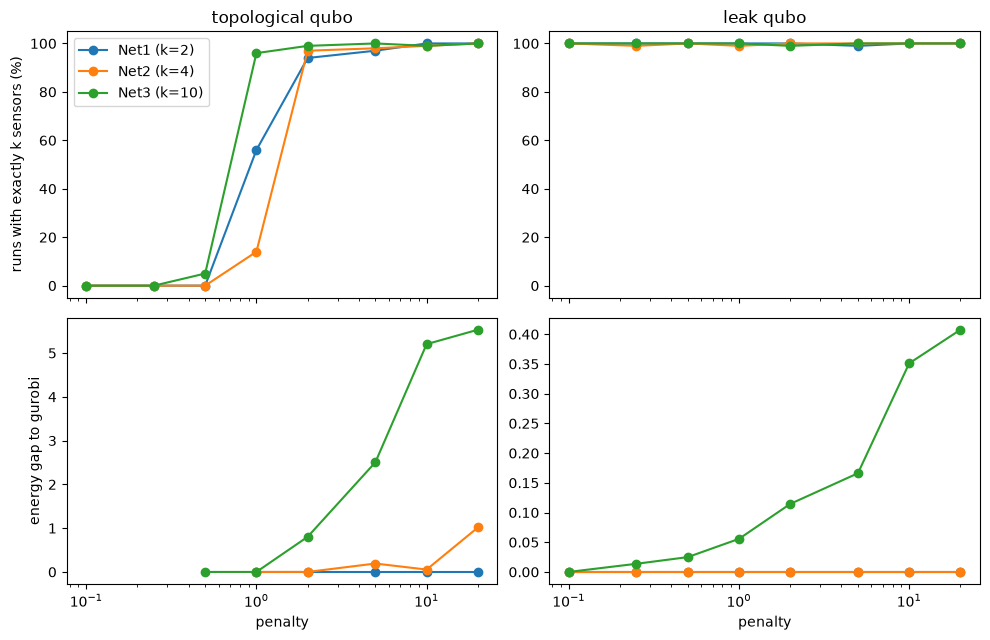

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
for col, qubo in enumerate(["topological", "leak"]):
    for network, k in problems:
        d = sweep[(sweep.qubo == qubo) & (sweep.network == network)]
        axes[0, col].plot(d["penalty"], d["valid %"], marker="o", label=f"{network} (k={k})")
        axes[1, col].plot(d["penalty"], d["gap"], marker="o")
    axes[0, col].set_title(f"{qubo} qubo")
    axes[0, col].set_ylim(-5, 105)
    axes[1, col].set_xlabel("penalty")
    axes[1, col].set_xscale("log")
axes[0, 0].set_ylabel("runs with exactly k sensors (%)")
axes[1, 0].set_ylabel("energy gap to gurobi")
axes[0, 0].legend()
plt.tight_layout()
plt.savefig("results/figures/penalty_sweep.png", dpi=200)

## Conclusion

- **Too small:** below a penalty of 1, the topological QUBO does not respect the budget.
- **Too large:** the gap to Gurobi grows with the penalty (Net3: 0 at penalty 1, 2.5 at penalty 5).
- **Leak QUBO:** respects the budget at every penalty we tried.

The best penalty is just above the minimum from section 1. Our starting value of 5 was too large.

# **Decision:** we set the penalty 10% above the biggest improvement one sensor can give (section 1),
# separately for each QUBO and network. Compared with our starting value of 5, this lowers the
# average SA gap on Net3 from 2.5 to 0.7 and the best SA solution still respects the budget in every case.